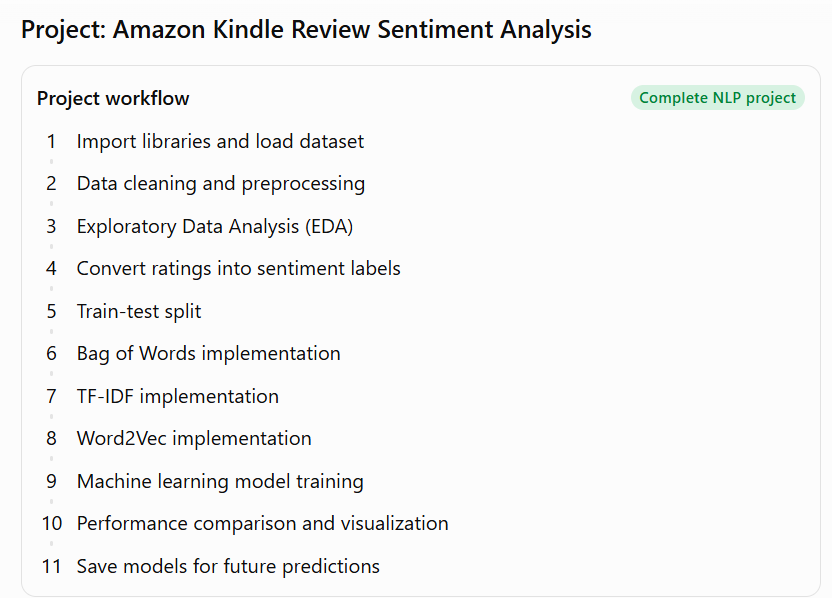

In [1]:

%pip install pandas numpy matplotlib seaborn scikit-learn gensim joblib


Note: you may need to restart the kernel to use updated packages.


In [2]:
# 1. Install and import libraries


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from gensim.models import Word2Vec

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
# 2. Load the Kindle dataset


df = pd.read_csv(
    r"C:\Users\MD Tajuddin\Downloads\all_kindle_review .csv.zip",
    usecols=["reviewText", "rating"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (12000, 2)


,rating,reviewText
0,3,"Jace Rankin may be short, but he's nothing to ..."
1,5,Great short read. I didn't want to put it dow...
2,3,I'll start by saying this is the first of four...
3,3,Aggie is Angela Lansbury who carries pocketboo...
4,4,I did not expect this type of book to be in li...


In [4]:
# 3. Data inspection

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   rating      12000 non-null  int64
 1   reviewText  12000 non-null  str  
dtypes: int64(1), str(1)
memory usage: 187.6 KB
None

Missing Values:
rating        0
reviewText    0
dtype: int64

Duplicate Values:
0

Rating Distribution:
rating
1    2000
2    2000
3    2000
4    3000
5    3000
Name: count, dtype: int64


In [5]:
# 4. Data cleaning

df = df.dropna(subset=["reviewText", "rating"])

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

df = df.dropna(subset=["rating"])

df = df.drop_duplicates(subset=["reviewText", "rating"])

df["reviewText"] = df["reviewText"].astype(str)

df = df.reset_index(drop=True)

print("After cleaning:", df.shape)
print(df.head())


After cleaning: (12000, 2)
   rating                                         reviewText
0       3  Jace Rankin may be short, but he's nothing to ...
1       5  Great short read.  I didn't want to put it dow...
2       3  I'll start by saying this is the first of four...
3       3  Aggie is Angela Lansbury who carries pocketboo...
4       4  I did not expect this type of book to be in li...


In [6]:
# 5. Text preprocessing

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<.*?>", " ", text)

    text = re.sub(r"[^a-z\s']", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["cleaned_review"] = df["reviewText"].apply(clean_text)

df[["reviewText", "cleaned_review"]].head()


,reviewText,cleaned_review
0,"Jace Rankin may be short, but he's nothing to ...",jace rankin may be short but he's nothing to m...
1,Great short read. I didn't want to put it dow...,great short read i didn't want to put it down ...
2,I'll start by saying this is the first of four...,i'll start by saying this is the first of four...
3,Aggie is Angela Lansbury who carries pocketboo...,aggie is angela lansbury who carries pocketboo...
4,I did not expect this type of book to be in li...,i did not expect this type of book to be in li...


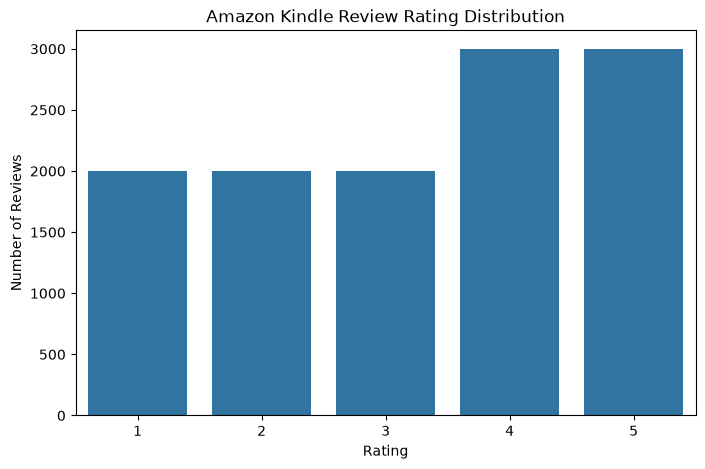

In [7]:
# 6. Exploratory Data Analysis (EDA)


plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="rating")

plt.title("Amazon Kindle Review Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()


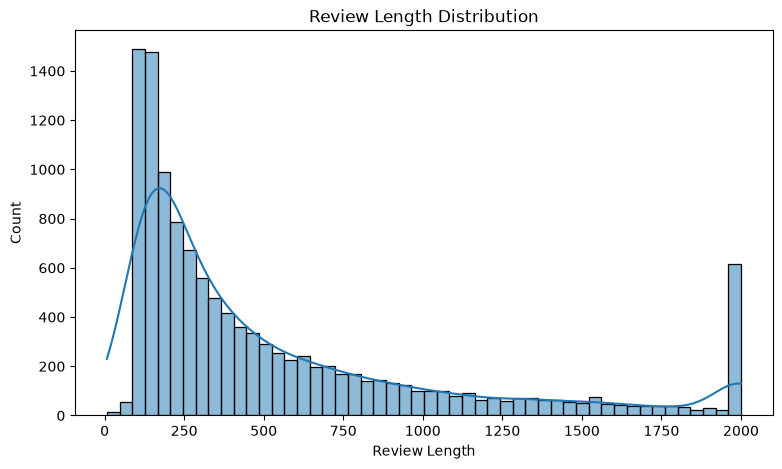

In [8]:
# B. Review length distribution

df["review_length"] = df["cleaned_review"].apply(len)

plt.figure(figsize=(9, 5))

sns.histplot(
    df["review_length"].clip(upper=2000),
    bins=50,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.show()


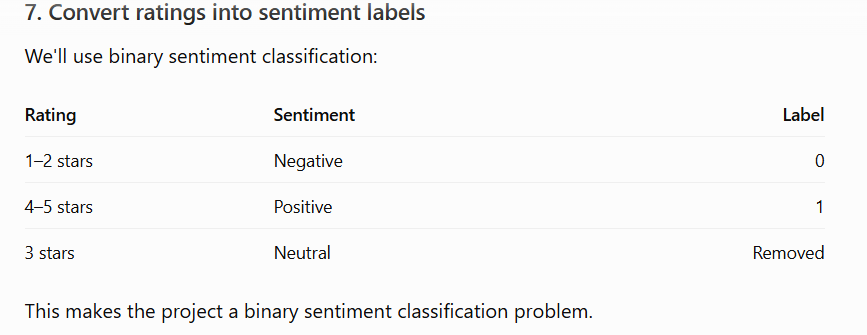

In [9]:

df = df[df["rating"].isin([1, 2, 4, 5])].copy()

df["sentiment"] = df["rating"].apply(
    lambda x: 1 if x >= 4 else 0
)

print(df["sentiment"].value_counts())

print("\nSentiment Labels:")
print(df[["cleaned_review", "rating", "sentiment"]].head())


sentiment
1    6000
0    4000
Name: count, dtype: int64

Sentiment Labels:
                                      cleaned_review  rating  sentiment
1  great short read i didn't want to put it down ...       5          1
4  i did not expect this type of book to be in li...       4          1
5  aislinn is a little girl with big dreams after...       5          1
6  this has the makings of a good story unfortuna...       2          0
7  i got this because i like collaborated short s...       4          1


#### 8. Train-test split
To prevent memory problems while you initially test the complete notebook, start with 100,000 reviews.

In [10]:

MAX_ROWS = 100_000

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    project_df = df.sample(
        n=MAX_ROWS,
        random_state=42,
        stratify=df["sentiment"]
    ).copy()
else:
    project_df = df.copy()

X = project_df["cleaned_review"]
y = project_df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training data: (8000,)
Testing data: (2000,)
Training labels: (8000,)
Testing labels: (2000,)


#### Part A: Bag of Words implementation
9. Apply CountVectorizer

This creates numerical word-frequency features.

In [11]:

bow_vectorizer = CountVectorizer(
    max_features=20000,
    min_df=2,
    max_df=0.95,
    dtype=np.int32
)

X_train_bow = bow_vectorizer.fit_transform(X_train)

X_test_bow = bow_vectorizer.transform(X_test)

print("BoW Training:", X_train_bow.shape)
print("BoW Testing:", X_test_bow.shape)

print("Matrix Type:", type(X_train_bow))


BoW Training: (8000, 13982)
BoW Testing: (2000, 13982)
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>


In [12]:
#10. Train Bag of Words model
#We'll use Multinomial Naive Bayes. 


bow_model = MultinomialNB()

bow_model.fit(X_train_bow, y_train)

bow_pred = bow_model.predict(X_test_bow)

print("BoW Accuracy:",
      accuracy_score(y_test, bow_pred))

print("\nClassification Report:")
print(classification_report(y_test, bow_pred))


BoW Accuracy: 0.8785

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.92      0.86       800
           1       0.94      0.85      0.89      1200

    accuracy                           0.88      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.89      0.88      0.88      2000



#### Part B: TF-IDF implementation
11. Apply TfidfVectorizer

In [13]:

tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    max_df=0.95,
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF Training:", X_train_tfidf.shape)
print("TF-IDF Testing:", X_test_tfidf.shape)


TF-IDF Training: (8000, 13982)
TF-IDF Testing: (2000, 13982)


In [14]:
## Trqin TF-IDF Model.

tfidf_model = LogisticRegression(
    max_iter=300,
    solver="liblinear"
)

tfidf_model.fit(X_train_tfidf, y_train)

tfidf_pred = tfidf_model.predict(X_test_tfidf)

print("TF-IDF Accuracy:",
      accuracy_score(y_test, tfidf_pred))

print("\nClassification Report:")
print(classification_report(y_test, tfidf_pred))


TF-IDF Accuracy: 0.8855

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85       800
           1       0.89      0.93      0.91      1200

    accuracy                           0.89      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.89      0.89      0.88      2000



#### Part C: Word2Vec implementation

13. Tokenize the reviews

In [15]:

X_train_tokens = X_train.apply(str.split)
X_test_tokens = X_test.apply(str.split)

print("Original Review:")
print(X_train.iloc[0])

print("\nTokenized Review:")
print(X_train_tokens.iloc[0])


Original Review:
ok i was really getting into the story and then it stopped the description didn't say it was a sample am i missing something

Tokenized Review:
['ok', 'i', 'was', 'really', 'getting', 'into', 'the', 'story', 'and', 'then', 'it', 'stopped', 'the', 'description', "didn't", 'say', 'it', 'was', 'a', 'sample', 'am', 'i', 'missing', 'something']


In [16]:
## Train Word2Vec Model.


word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=50,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=5
)

print("Word2Vec training completed!")

print("Vocabulary Size:",
      len(word2vec_model.wv))

print("Vector Size:",
      word2vec_model.vector_size)


Word2Vec training completed!
Vocabulary Size: 15386
Vector Size: 50


In [18]:
## 15. Check Individual word vector.


word = "love"

if word in word2vec_model.wv:

    print("Word:", word)

    print("Vector:")
    print(word2vec_model.wv[word])

    print("Shape:",
          word2vec_model.wv[word].shape)

else:
    print("Word not found in vocabulary")


Word: love
Vector:
[ 0.02378236  0.19570182  0.05347287  0.33931357  0.11545772 -0.39564568
  0.13855077  0.6151417  -0.47261173  0.4567036  -0.19469547 -0.5706414
  0.47213107  0.39366776 -0.39590555  0.2884496   0.35047984 -0.14270273
  0.00671241 -0.1560442   0.8369383   1.028185    0.63753164 -0.25665477
  0.5343331  -0.552572   -0.25585374 -0.2201772   0.11807505  0.5188276
 -0.41036686 -0.23850882 -0.126112   -0.10405317 -0.5623979   0.11393896
  0.08378424  0.00222553 -0.18532448 -0.27794817  0.20132221 -0.24132246
 -0.6316123  -0.4065365   0.45222518 -0.31311616  0.24844691 -0.4688185
  0.26419118 -0.01372007]
Shape: (50,)


In [19]:
# 16. Find similar words.

#One useful feature of Word2Vec is that it can find semantically similar words.

word = "good"

if word in word2vec_model.wv:

    similar_words = word2vec_model.wv.most_similar(
        word,
        topn=10
    )

    print("Words similar to:", word)

    for w, score in similar_words:
        print(w, score)


Words similar to: good
great 0.8929510116577148
decent 0.8557849526405334
cool 0.8397738933563232
nice 0.8326837420463562
rare 0.8254216909408569
scary 0.8251636624336243
pleasant 0.8176225423812866
brilliant 0.8165013194084167
neat 0.8148216605186462
clever 0.8124489784240723


#### 17. Convert complete reviews into Word2Vec vectors
Word2Vec produces a vector for each word. We'll take the average of the word vectors to represent each complete review.

In [20]:

def document_vector(words, model):

    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(
            model.vector_size,
            dtype=np.float32
        )

    return np.mean(vectors, axis=0).astype(np.float32)


In [21]:
# 18. Convert Training and testing reviews.


X_train_w2v = np.vstack([
    document_vector(words, word2vec_model)
    for words in X_train_tokens
])

X_test_w2v = np.vstack([
    document_vector(words, word2vec_model)
    for words in X_test_tokens
])

print("Word2Vec Training Shape:",
      X_train_w2v.shape)

print("Word2Vec Testing Shape:",
      X_test_w2v.shape)


Word2Vec Training Shape: (8000, 50)
Word2Vec Testing Shape: (2000, 50)


In [22]:
# 19. Train Word2Vec classification model


w2v_model = SGDClassifier(
    loss="log_loss",
    max_iter=20,
    random_state=42,
    tol=1e-3
)

w2v_model.fit(X_train_w2v, y_train)

w2v_pred = w2v_model.predict(X_test_w2v)

print("Word2Vec Accuracy:",
      accuracy_score(y_test, w2v_pred))

print("\nClassification Report:")
print(classification_report(y_test, w2v_pred))


Word2Vec Accuracy: 0.842

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.87      0.82       800
           1       0.91      0.82      0.86      1200

    accuracy                           0.84      2000
   macro avg       0.84      0.85      0.84      2000
weighted avg       0.85      0.84      0.84      2000



#### Part D: Compare all three techniques
20. Create a performance comparison table.

We will compare accuracy, precision, recall and F1-score.

In [23]:

results = []

predictions = {
    "Bag of Words": bow_pred,
    "TF-IDF": tfidf_pred,
    "Word2Vec": w2v_pred
}

for name, pred in predictions.items():

    results.append({
        "Technique": name,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        )
    })


results_df = pd.DataFrame(results)

print(results_df)


      Technique  Accuracy  Precision    Recall  F1 Score
0  Bag of Words    0.8785   0.941828  0.850000  0.893561
1        TF-IDF    0.8855   0.888711  0.925000  0.906492
2      Word2Vec    0.8420   0.906998  0.820833  0.861767


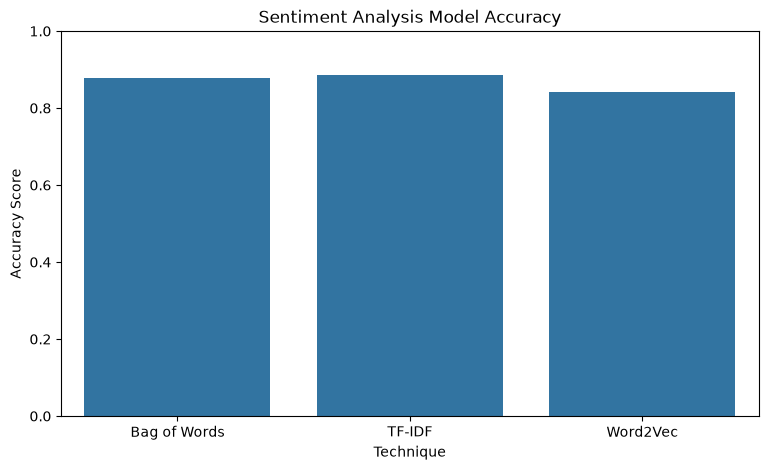

In [24]:
# 21. Visualize model accuracy


plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Technique",
    y="Accuracy"
)

plt.title("Sentiment Analysis Model Accuracy")

plt.ylim(0, 1)

plt.ylabel("Accuracy Score")

plt.show()


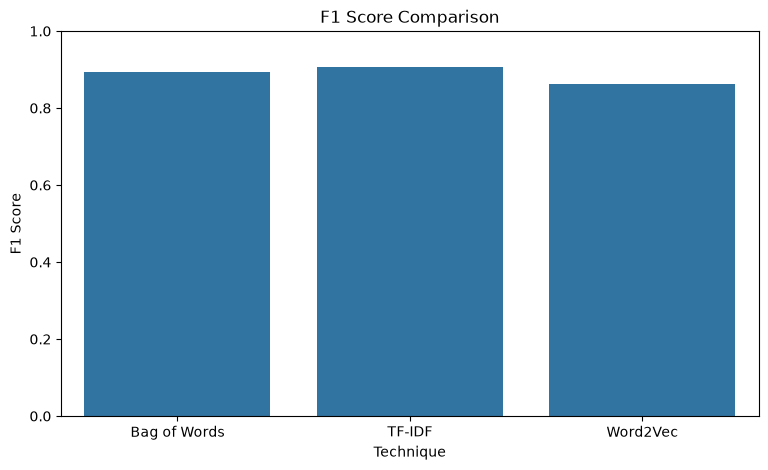

In [25]:
#   22. Compare F1-scores


plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Technique",
    y="F1 Score"
)

plt.title("F1 Score Comparison")

plt.ylim(0, 1)

plt.show()


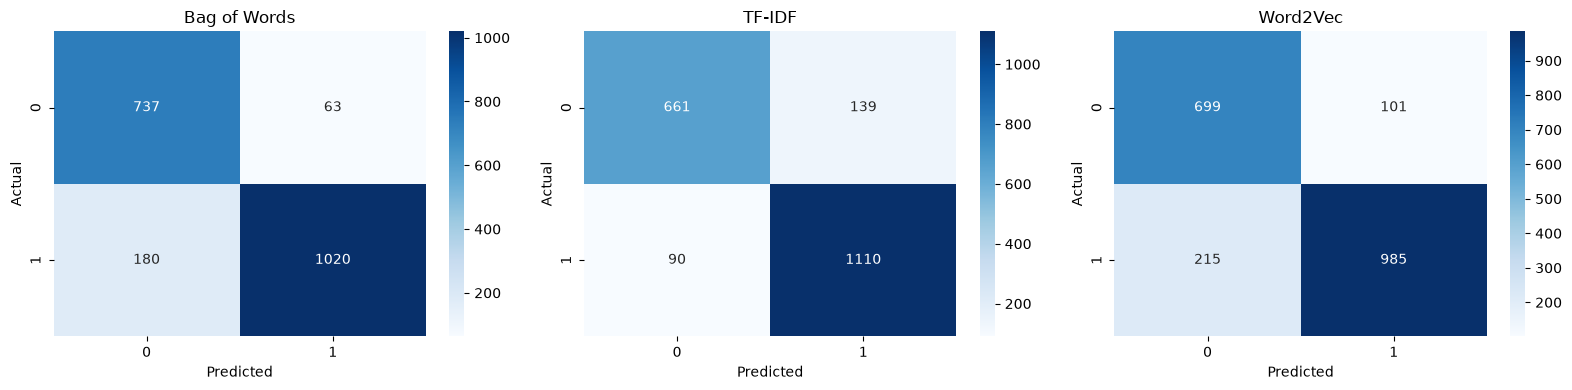

In [26]:
# 23. Confusion Matrices.


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


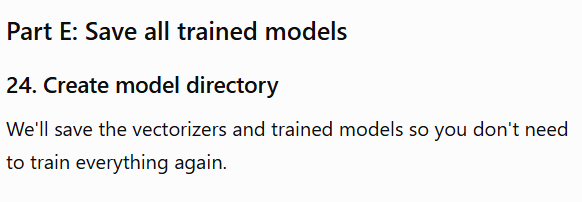

In [27]:

os.makedirs("models", exist_ok=True)

# Save Bag of Words
joblib.dump(bow_vectorizer, "models/bow_vectorizer.pkl")
joblib.dump(bow_model, "models/bow_model.pkl")

# Save TF-IDF
joblib.dump(tfidf_vectorizer, "models/tfidf_vectorizer.pkl")
joblib.dump(tfidf_model, "models/tfidf_model.pkl")

# Save Word2Vec
word2vec_model.save("models/word2vec.model")
joblib.dump(w2v_model, "models/word2vec_classifier.pkl")

# Save performance results
results_df.to_csv("models/model_comparison.csv", index=False)

print("All models saved successfully!")


All models saved successfully!


#### 25. Test your project with a new review.

Now let's test whether your trained models can identify positive or negative sentiment.

In [28]:

def predict_sentiment(review):

    cleaned = clean_text(review)

    # Bag of Words
    bow_features = bow_vectorizer.transform([cleaned])
    bow_result = bow_model.predict(bow_features)[0]

    # TF-IDF
    tfidf_features = tfidf_vectorizer.transform([cleaned])
    tfidf_result = tfidf_model.predict(tfidf_features)[0]

    # Word2Vec
    tokens = cleaned.split()

    w2v_features = document_vector(
        tokens,
        word2vec_model
    ).reshape(1, -1)

    w2v_result = w2v_model.predict(w2v_features)[0]

    labels = {
        0: "Negative",
        1: "Positive"
    }

    print("Review:", review)

    print("\nBag of Words:", labels[bow_result])
    print("TF-IDF:", labels[tfidf_result])
    print("Word2Vec:", labels[w2v_result])


predict_sentiment(
    "This Kindle book is amazing. I really enjoyed reading it."
)


Review: This Kindle book is amazing. I really enjoyed reading it.

Bag of Words: Positive
TF-IDF: Positive
Word2Vec: Positive


In [29]:
# Another example.

predict_sentiment(
    "This book is terrible, boring and a complete waste of money."
)

Review: This book is terrible, boring and a complete waste of money.

Bag of Words: Negative
TF-IDF: Negative
Word2Vec: Negative


#### 26. Final project evaluation
Display the best-performing technique:

In [30]:

best_model = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]

print("Best Performing Technique:",
      best_model["Technique"])

print("Accuracy:",
      round(best_model["Accuracy"] * 100, 2), "%")

print("F1 Score:",
      round(best_model["F1 Score"], 4))


Best Performing Technique: TF-IDF
Accuracy: 88.55 %
F1 Score: 0.9065
